# Section 1 — Taylor Series and Error

[← Module 1](README.md) · [Next: Floating-Point Arithmetic →](02_floating_point_and_error.ipynb)

Taylor polynomials replace a smooth function by a polynomial near a chosen center $x_0$.
The notation here follows the course lectures and the standard presentation in Brin and
Burden & Faires.

For $f\in C^{n+1}$, the degree-$n$ Taylor polynomial about $x_0$ is

$$
P_n(x)=\sum_{k=0}^{n}\frac{f^{(k)}(x_0)}{k!}(x-x_0)^k.
$$

Taylor's theorem writes

$$
f(x)=P_n(x)+R_n(x),
$$

where the Lagrange remainder is

$$
R_n(x)=\frac{f^{(n+1)}(\xi)}{(n+1)!}(x-x_0)^{n+1}
$$

for some $\xi$ between $x$ and $x_0$.

### Learning goals
- construct a Taylor polynomial;
- use it to approximate a function value;
- compute the actual error;
- obtain a rigorous error bound from the remainder term;
- see how the approximation changes as the degree increases.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

## Example: approximate $\ln(1.8)$ about $x_0=1$

For $f(x)=\ln(x)$,

$$
f(1)=0,\qquad f'(1)=1,\qquad f''(1)=-1.
$$

Thus

$$
P_2(x)=(x-1)-\frac{(x-1)^2}{2}.
$$

In [2]:
def p2_log(x):
    """Return the second-degree Taylor polynomial for ln(x) about x0 = 1."""
    return (x - 1.0) - 0.5 * (x - 1.0) ** 2


x_value = 1.8
approximation = p2_log(x_value)
exact_value = math.log(x_value)
actual_error = abs(exact_value - approximation)

print(f"P2(1.8)       = {approximation:.10f}")
print(f"ln(1.8)       = {exact_value:.10f}")
print(f"actual error  = {actual_error:.10f}")

P2(1.8)       = 0.4800000000
ln(1.8)       = 0.5877866649
actual error  = 0.1077866649


### Error bound

Here

$$
f'''(x)=\frac{2}{x^3}.
$$

For $x\in[1,1.8]$,

$$
|f'''(x)|\le 2.
$$

Therefore

$$
|R_2(1.8)|
\le
\frac{2}{3!}|1.8-1|^3.
$$

In [3]:
m_value = 2.0
error_bound = m_value * abs(x_value - 1.0) ** 3 / math.factorial(3)

print(f"error bound   = {error_bound:.10f}")
print(f"actual error  = {actual_error:.10f}")

error bound   = 0.1706666667
actual error  = 0.1077866649


## Visualizing the Taylor approximation

The approximation is best near the center $x_0=1$. The next plot compares
$\ln(x)$ with $P_1$, $P_2$, and $P_3$.

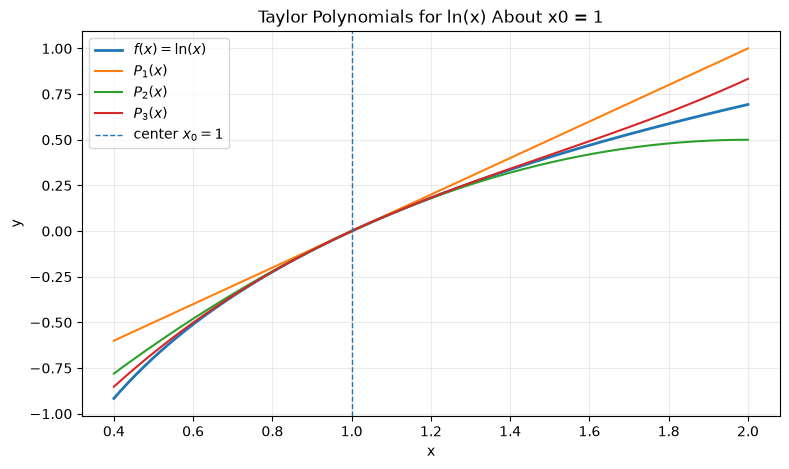

In [4]:
def p1_log(x):
    return x - 1.0


def p3_log(x):
    return (x - 1.0) - 0.5 * (x - 1.0) ** 2 + (x - 1.0) ** 3 / 3.0


x_values = np.linspace(0.4, 2.0, 400)

plt.figure(figsize=(9, 5))
plt.plot(x_values, np.log(x_values), label=r"$f(x)=\ln(x)$", linewidth=2)
plt.plot(x_values, p1_log(x_values), label=r"$P_1(x)$")
plt.plot(x_values, p2_log(x_values), label=r"$P_2(x)$")
plt.plot(x_values, p3_log(x_values), label=r"$P_3(x)$")
plt.axvline(1.0, linestyle="--", linewidth=1, label=r"center $x_0=1$")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Taylor Polynomials for ln(x) About x0 = 1")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## How many terms do we need?

A common numerical-analysis question is not just *what is the approximation?* but
*how many terms guarantee a desired accuracy?*

For $e^{-x}$ about $x_0=0$,

$$
P_n(x)=\sum_{k=0}^{n}\frac{(-1)^k x^k}{k!}.
$$

The following computation finds the smallest degree for which the Lagrange bound at
$x=0.5$ is below $10^{-6}$.

In [5]:
tolerance = 1.0e-6
x_value = 0.5

for degree in range(20):
    remainder_bound = x_value ** (degree + 1) / math.factorial(degree + 1)
    if remainder_bound < tolerance:
        print(f"smallest degree n = {degree}")
        print(f"guaranteed bound  = {remainder_bound:.3e}")
        break

smallest degree n = 7
guaranteed bound  = 9.688e-08


### References

- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.

[← Module 1](README.md) · [Next: Floating-Point Arithmetic →](02_floating_point_and_error.ipynb)